# k-means applied to image segmentation

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from ipywidgets import interact, IntSlider

A color image is an array with three numbers for each pixel: the amounts of red, green and blue. If we forget where each pixel is, the image is a cloud of points in a space of three dimensions, and we can cluster them with k-means. Replacing each pixel by the centroid of its cluster gives an image with only $k$ colors: the pixels of similar color are grouped (segmentation), and the image needs much less storage (color quantization).

In [2]:
img = plt.imread('gir.jpg')
img = img/255
n1, n2, p = img.shape
img_flat = img.reshape(n1*n2, p)

print('Size of the image:', n1, 'x', n2, 'pixels, with', p, 'colors each')
print('Different colors in the image:', len(np.unique((img_flat*255).astype(int), axis=0)))

Size of the image: 768 x 1024 pixels, with 3 colors each


Different colors in the image: 27698


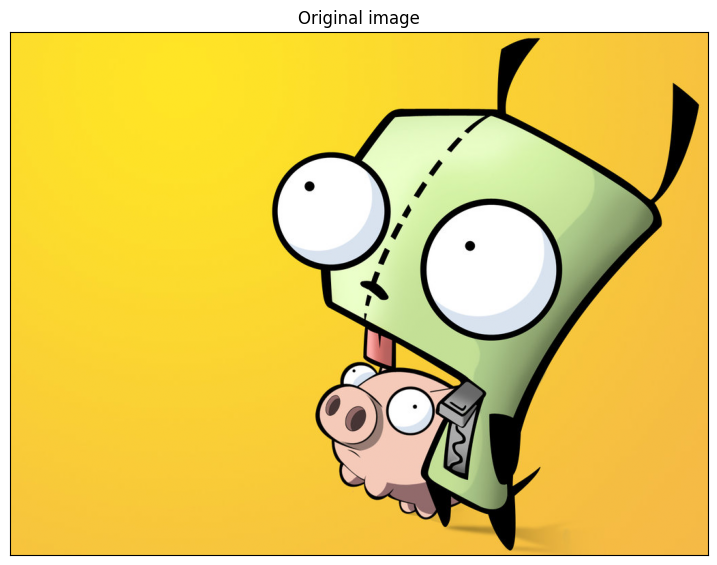

In [3]:
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(img)
ax.set_xticks([])
ax.set_yticks([])
ax.set_title('Original image');

## The pixels as points

A sample of the pixels in the space of colors, each one drawn with its own color (two projections of the three dimensions).

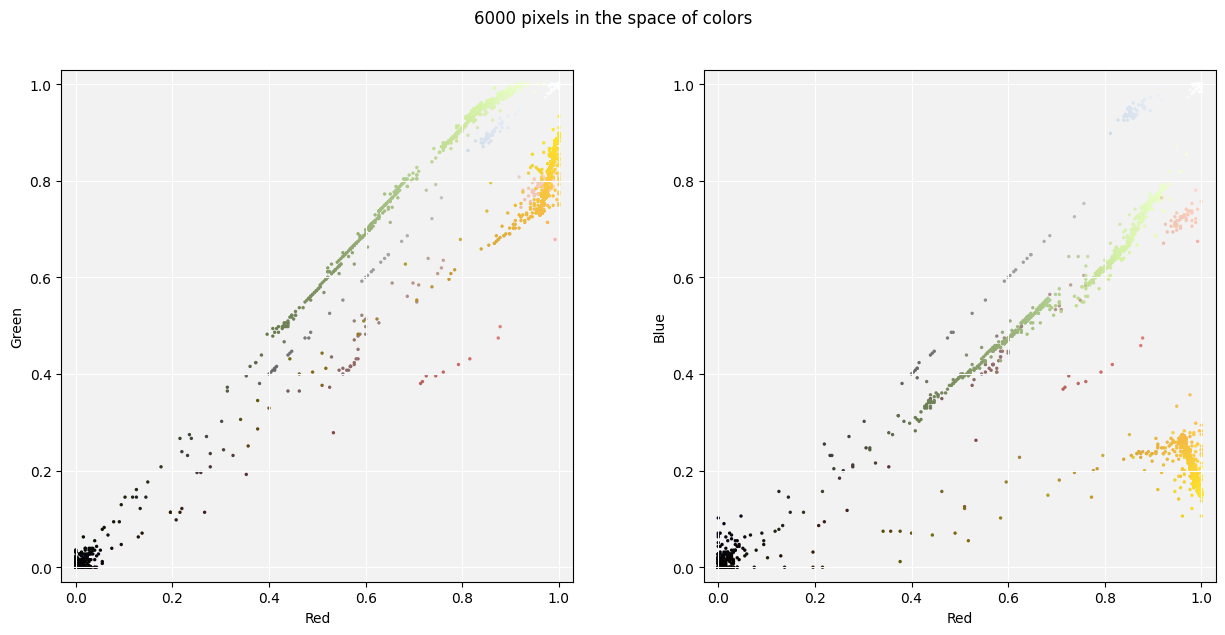

In [4]:
rng = np.random.default_rng(111)
sample = rng.choice(n1*n2, size=6000, replace=False)

def plot_pixels(axes, colors, centers=None):
    for ax, (i, j) in zip(axes, [(0, 1), (0, 2)]):
        ax.scatter(img_flat[sample, i], img_flat[sample, j], c=colors, s=6, linewidths=0)
        if centers is not None:
            ax.scatter(centers[:, i], centers[:, j], c=centers, s=260, edgecolors='black', linewidths=1.5, zorder=5)
        ax.set_xlabel(['Red', 'Green', 'Blue'][i])
        ax.set_ylabel(['Red', 'Green', 'Blue'][j])
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)
        ax.set_aspect('equal')
        ax.set_facecolor('#f2f2f2')
        ax.grid(True, color='white')

fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
plot_pixels(axes, img_flat[sample])
fig.suptitle('6000 pixels in the space of colors')
fig.tight_layout(rect=(0, 0, 1, 0.96))

## Two clusters

In [5]:
def segment(k, random_state=111, init='k-means++', n_init=10):
    # Fit k-means to the pixels and rebuild the image with the color of the centroids
    kmeans = KMeans(n_clusters=k, random_state=random_state, init=init, n_init=n_init)
    kmeans = kmeans.fit(img_flat)
    img_recons = kmeans.cluster_centers_[kmeans.labels_].reshape(n1, n2, p)
    return kmeans, img_recons

def plot_segmentation(ax, kmeans, img_recons, title):
    ax.imshow(np.clip(img_recons, 0, 1))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    # The colors of the centroids, with a width proportional to the size of the cluster
    sizes = np.bincount(kmeans.labels_, minlength=len(kmeans.cluster_centers_))/len(kmeans.labels_)
    order = np.argsort(-sizes)
    left = 0
    strip = ax.inset_axes([0, -0.09, 1, 0.06])
    for c in order:
        strip.barh(0, sizes[c], left=left, color=np.clip(kmeans.cluster_centers_[c], 0, 1), edgecolor='black', linewidth=0.5)
        left += sizes[c]
    strip.set_xlim(0, 1)
    strip.set_axis_off()

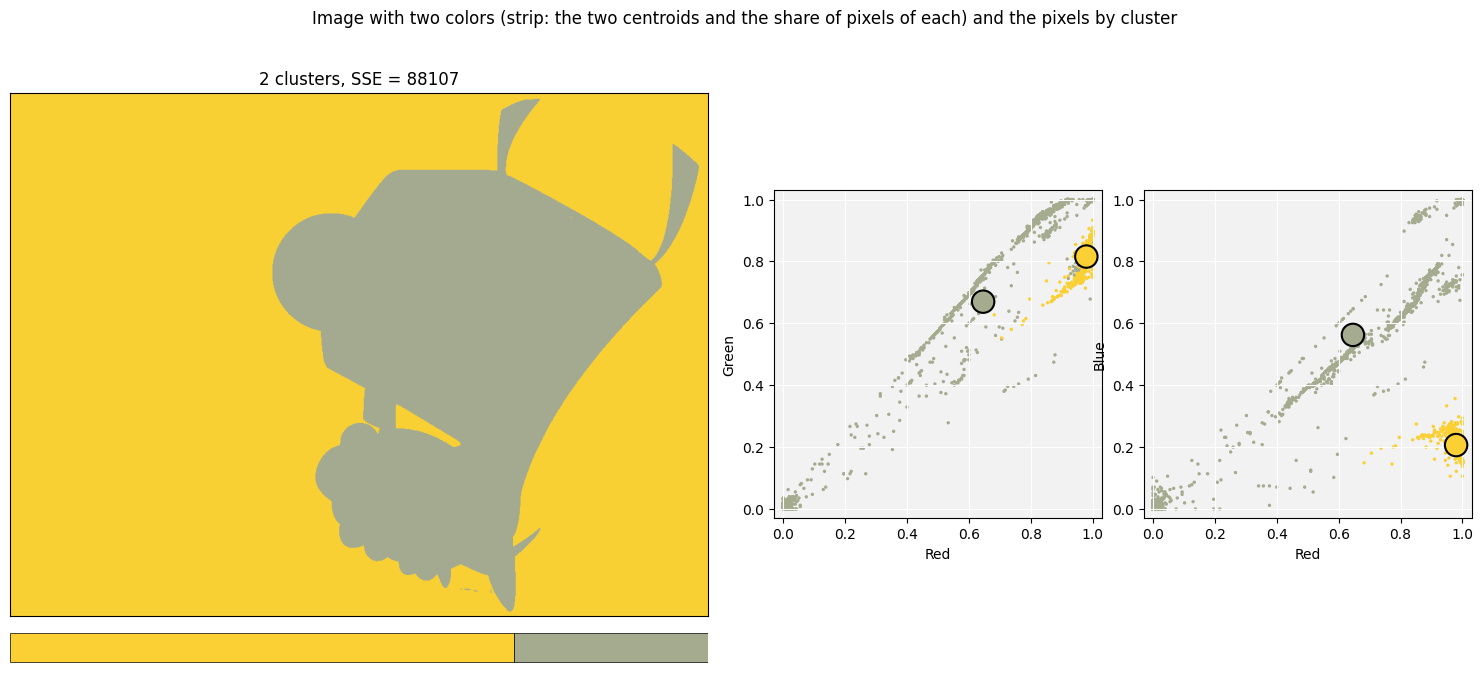

In [6]:
kmeans, img_recons = segment(2, random_state=111, init='random', n_init=1)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_segmentation(axes[0], kmeans, img_recons, f'2 clusters, SSE = {kmeans.inertia_:.0f}')
axes[1].set_axis_off()
plot_pixels([axes[1].inset_axes([0.0, 0.05, 0.47, 0.9]), axes[1].inset_axes([0.53, 0.05, 0.47, 0.9])],
            kmeans.cluster_centers_[kmeans.labels_[sample]], kmeans.cluster_centers_)
fig.suptitle('Image with two colors (strip: the two centroids and the share of pixels of each) and the pixels by cluster')
fig.tight_layout(rect=(0, 0, 1, 0.95))

We ran k-means once, from random initial centroids. But k-means only finds a local minimum, which depends on the initial centroids: with another seed the result is a different segmentation, with a much smaller SSE. That is why `KMeans` can repeat the algorithm `n_init` times and keep the best solution; from now on we use `n_init=10`.

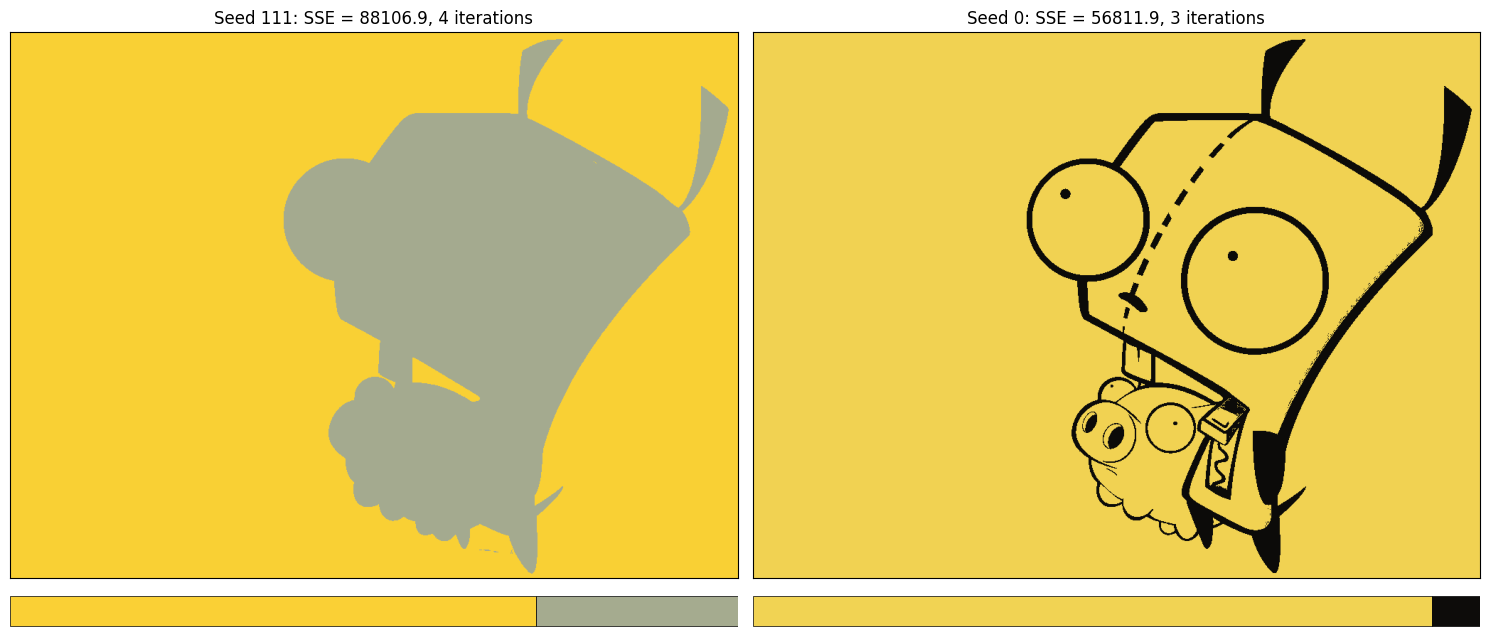

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, seed in zip(axes, [111, 0]):
    kmeans, img_recons = segment(2, random_state=seed, init='random', n_init=1)
    plot_segmentation(ax, kmeans, img_recons, f'Seed {seed}: SSE = {kmeans.inertia_:.1f}, {kmeans.n_iter_} iterations')
plt.tight_layout()

## More clusters

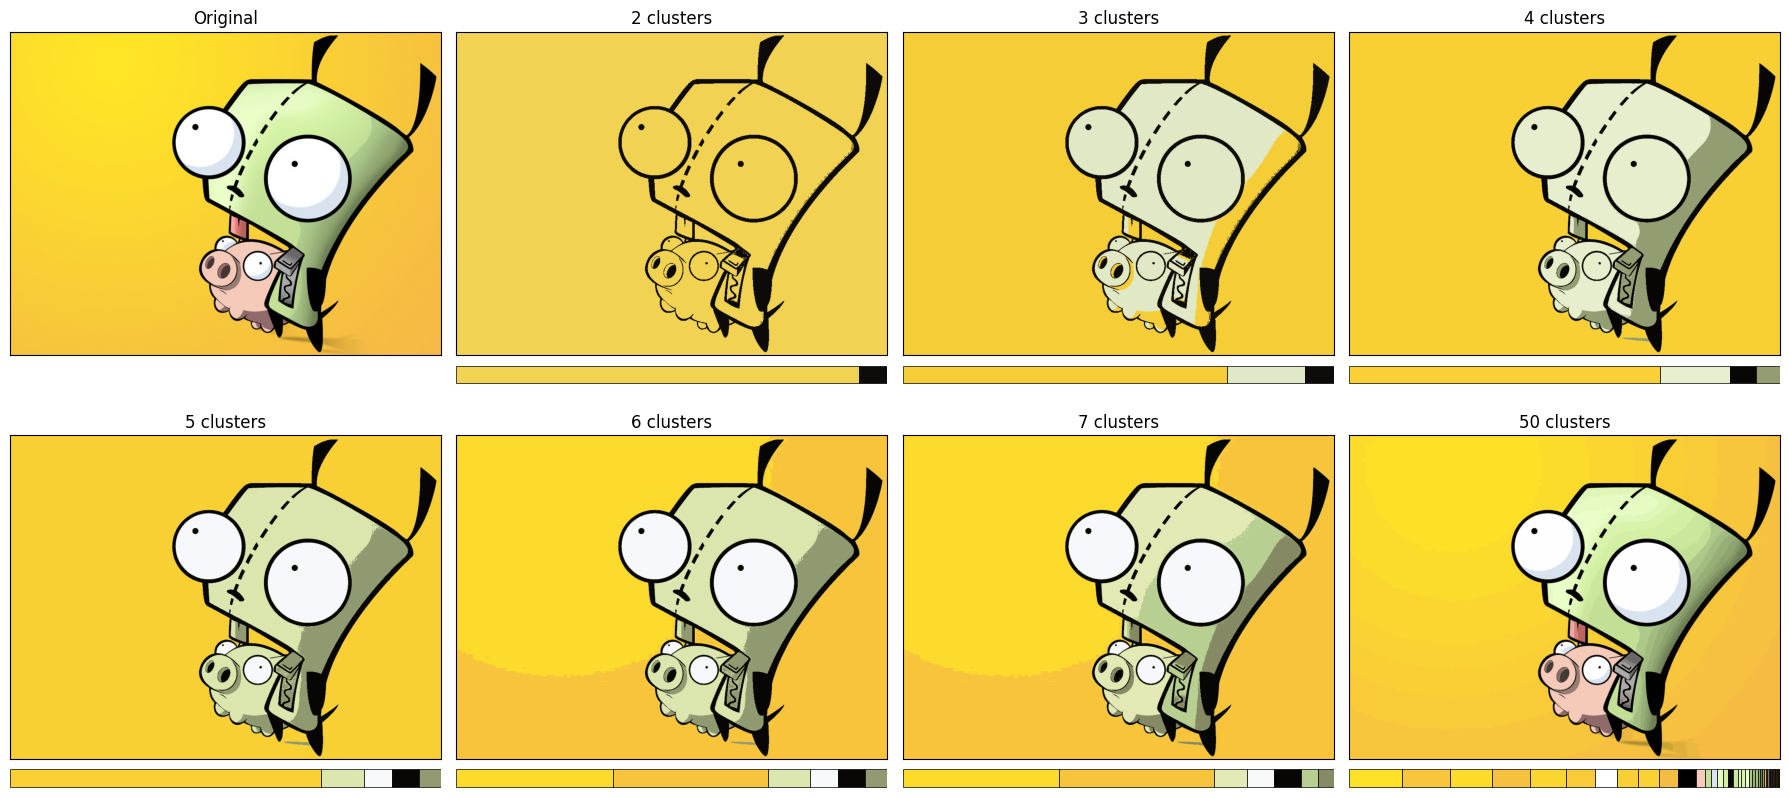

In [8]:
n_cluster = [2,3,4,5,6,7,50]
results = {k: segment(k) for k in n_cluster}

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
axes[0, 0].imshow(img)
axes[0, 0].set_xticks([])
axes[0, 0].set_yticks([])
axes[0, 0].set_title('Original')
for ax, k in zip(axes.ravel()[1:], n_cluster):
    plot_segmentation(ax, *results[k], f'{k} clusters')
plt.tight_layout()

With 50 colors the image is almost indistinguishable from the original, which has tens of thousands of different colors.

## How many clusters?

The sum of squared distances of the pixels to their centroid (SSE), for 1 to 10 clusters, and its elbow: the point of the curve farthest from the line between its two ends, after scaling both axes to $[0, 1]$.

In [9]:
k_values = np.arange(1, 11)
sse = np.array([results[k][0].inertia_ if k in results else segment(k)[0].inertia_ for k in k_values])

def elbow(k_values, sse):
    x_norm = (k_values - k_values[0])/(k_values[-1] - k_values[0])
    y_norm = (sse - sse[-1])/(sse[0] - sse[-1])
    # The line joins (0, 1) and (1, 0): the distance to it is proportional to 1 - x - y
    distance = 1 - x_norm - y_norm
    return k_values[np.argmax(distance)]

k_elbow = elbow(k_values, sse)
print('Elbow:', k_elbow)

Elbow: 3


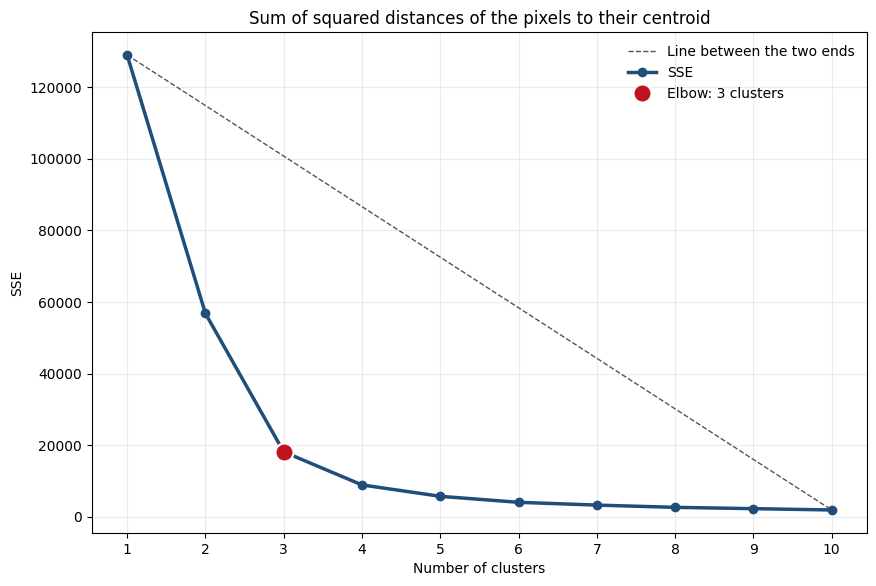

In [10]:
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot([k_values[0], k_values[-1]], [sse[0], sse[-1]], '--', color='#555555', lw=1, label='Line between the two ends')
ax.plot(k_values, sse, 'o-', color='#1f4e79', lw=2.5, label='SSE')
ax.plot(k_elbow, sse[k_elbow-1], 'o', color='#c1121f', markersize=13, markeredgecolor='white', markeredgewidth=1.5,
        label=f'Elbow: {k_elbow} clusters')
ax.set_xticks(k_values)
ax.set_xlabel('Number of clusters')
ax.set_ylabel('SSE')
ax.set_title('Sum of squared distances of the pixels to their centroid')
ax.legend(loc='upper right', frameon=False)
ax.grid(True, alpha=0.25)

## Choose the number of colors

Move the slider to change the number of clusters (this cell needs a running kernel; each change fits k-means to the 786432 pixels, it takes a few seconds).

In [11]:
def interactive_segmentation(k):
    kmeans, img_recons = segment(k, n_init=1)
    fig, ax = plt.subplots(figsize=(9, 7.5))
    plot_segmentation(ax, kmeans, img_recons, f'{k} clusters')
    plt.show()

interact(interactive_segmentation, k=IntSlider(value=k_elbow, min=1, max=30, description='clusters', continuous_update=False));

interactive(children=(IntSlider(value=3, continuous_update=False, description='clusters', max=30, min=1), Outp…

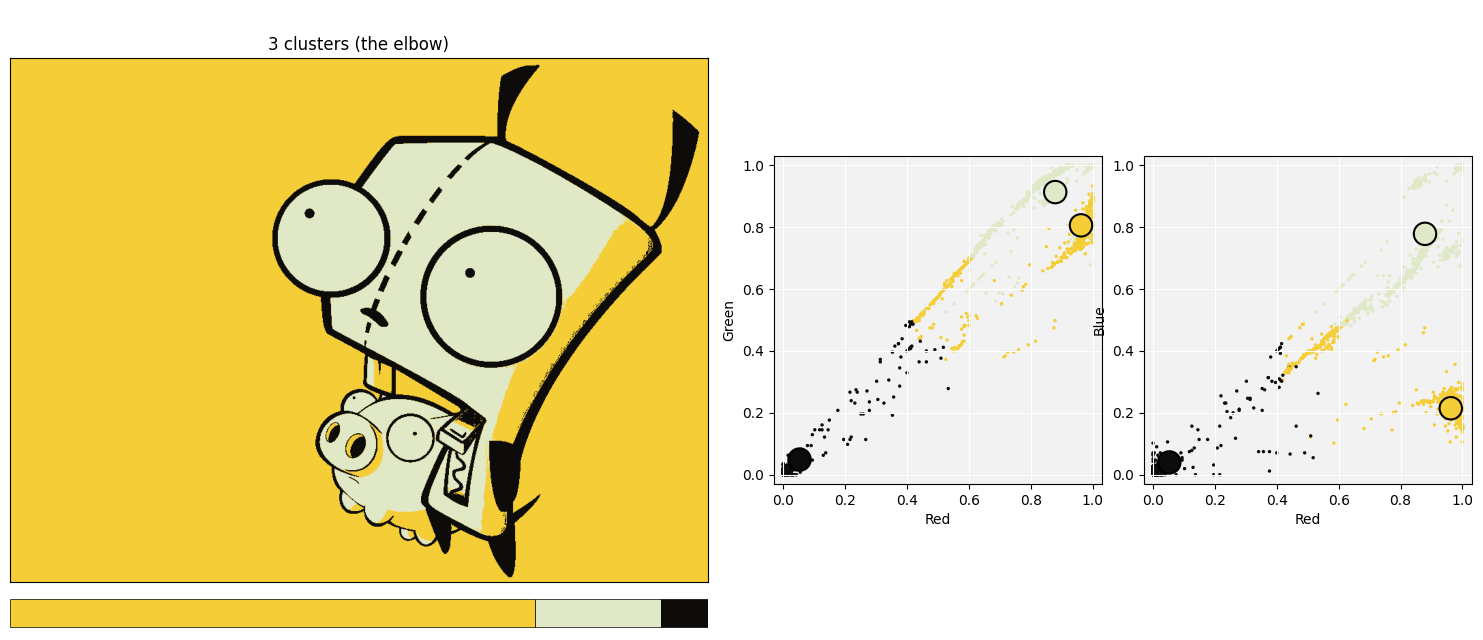

In [12]:
kmeans, img_recons = results[k_elbow] if k_elbow in results else segment(k_elbow)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
plot_segmentation(axes[0], kmeans, img_recons, f'{k_elbow} clusters (the elbow)')
axes[1].set_axis_off()
plot_pixels([axes[1].inset_axes([0.0, 0.05, 0.47, 0.9]), axes[1].inset_axes([0.53, 0.05, 0.47, 0.9])],
            kmeans.cluster_centers_[kmeans.labels_[sample]], kmeans.cluster_centers_)
plt.tight_layout()